# Notebook 05: Dirichlet Non-IID Client Partitioning & Statistical Heterogeneity

## 1. Formulation
To mirror real-world reader specialization across $K = 10$ edge clients, client topic proportions are drawn from a Dirichlet distribution $\mathbf{p}_k \sim \text{Dir}(\alpha \mathbf{p}_0)$ with $\alpha = 0.5$.
We quantify per-client divergence from the global uniform distribution $U = (1/3, 1/3, 1/3)$ using Kullback-Leibler divergence:
$$D_{\text{KL}}(P_k \| U) = \sum_{c=1}^{3} P_k(c) \ln \frac{P_k(c)}{1/3}$$

In [1]:
import os, sys, json, random
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

SEED = 42
random.seed(SEED)
np.random.seed(SEED)

# Resolve repository root deterministically from ml/notebooks/
REPO_ROOT = os.path.abspath(os.path.join(os.getcwd(), "..", ".."))
if REPO_ROOT not in sys.path:
    sys.path.insert(0, REPO_ROOT)

DATA_DIR = os.path.join(REPO_ROOT, "ml", "data", "processed")
ARTIFACTS_DIR = os.path.join(REPO_ROOT, "ml", "artifacts")
VIZ_DIR = os.path.join(REPO_ROOT, "ml", "visualizations")
plt.rcParams["figure.dpi"] = 110
import seaborn as sns

with open(os.path.join(DATA_DIR, "federated_partitions.json"), "r", encoding="utf-8") as f:
    part_json = json.load(f)

rows = []
for cid, pdata in part_json["non_iid_partitions"].items():
    shares = pdata["category_shares"]
    vec = np.array([shares.get("AI", 0.0), shares.get("Sports", 0.0), shares.get("History", 0.0)]) + 1e-9
    vec = vec / vec.sum()
    kl_div = float(np.sum(vec * np.log(vec / (1.0 / 3.0))))
    rows.append({
        "Client": cid,
        "Users": len(pdata["users"]),
        "Events": pdata["event_count"],
        "AI": shares.get("AI", 0.0),
        "Sports": shares.get("Sports", 0.0),
        "History": shares.get("History", 0.0),
        "KL_vs_Uniform": round(kl_div, 4),
    })

df_skew = pd.DataFrame(rows).set_index("Client")
print(f"Dirichlet Concentration alpha = {part_json['dirichlet_alpha']} | Clients = {part_json['num_clients']}")
print(df_skew.round(3).to_string())

Dirichlet Concentration alpha = 0.5 | Clients = 10
          Users  Events     AI  Sports  History  KL_vs_Uniform
Client                                                        
client_0     14     682  0.282   0.317    0.402          0.011
client_1      9     411  0.290   0.511    0.200          0.075
client_2     10     532  0.395   0.258    0.348          0.015
client_3     16     761  0.359   0.242    0.399          0.021
client_4      9     364  0.283   0.442    0.275          0.026
client_5      9     465  0.308   0.402    0.290          0.011
client_6      9     435  0.349   0.349    0.301          0.002
client_7     10     472  0.445   0.311    0.244          0.031
client_8      5     285  0.635   0.147    0.218          0.196
client_9      9     458  0.129   0.428    0.443          0.111


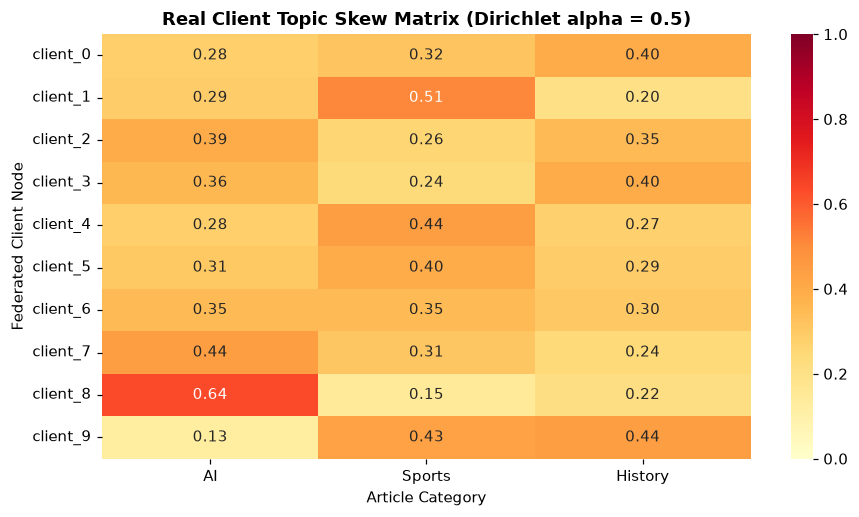

In [2]:
plt.figure(figsize=(8.5, 4.8))
sns.heatmap(df_skew[["AI", "Sports", "History"]], annot=True, fmt=".2f", cmap="YlOrRd", vmin=0, vmax=1)
plt.title(f"Real Client Topic Skew Matrix (Dirichlet alpha = {part_json['dirichlet_alpha']})", fontweight="bold")
plt.xlabel("Article Category")
plt.ylabel("Federated Client Node")
plt.tight_layout()
plt.show()